MATSim: 34461 persons, 34461 with valid age and sex
Mikrozensus read with encoding: cp1252
Mikrozensus: 57090 persons, 57090 with valid age and sex


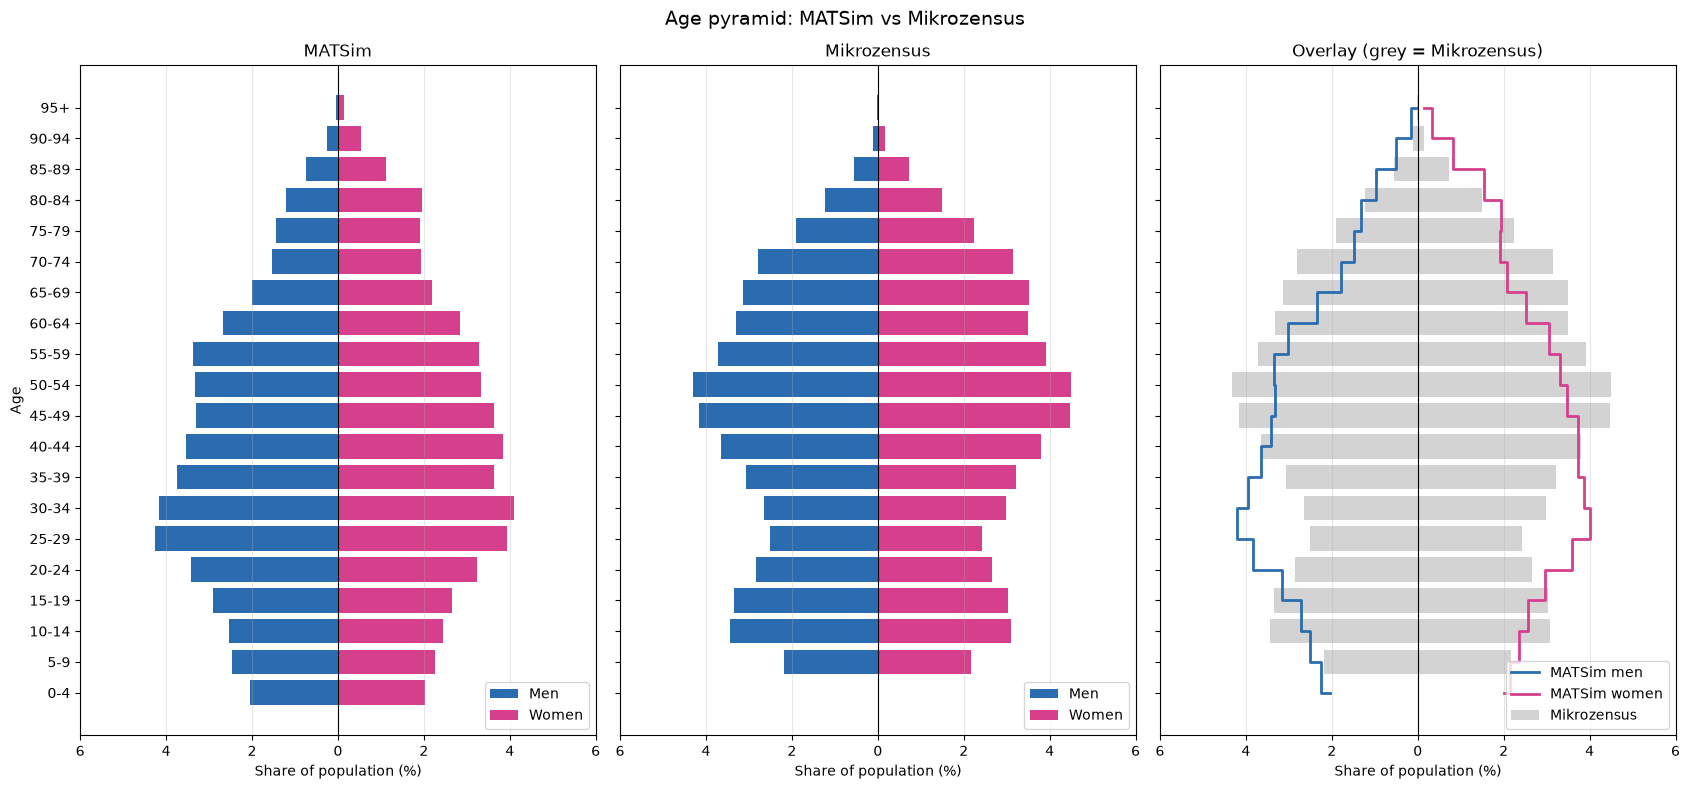

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [ ]:
"""
Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)
Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
unweighted
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_WIDTH = 5
MAX_AGE = 100
BINS = list(range(0, MAX_AGE + BIN_WIDTH, BIN_WIDTH))
LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
    rows = []
    person = None
    in_plan = False
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
                elif tag == "plan":
                    in_plan = True
            else:
                if tag == "attribute" and person is not None and not in_plan:
                    name = elem.get("name")
                    if name in ("age", "sex", "gender"):
                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()
    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
    n0 = len(df)
    df = df.dropna(subset=["age", "sex"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python",
                             usecols=["alter", "gesl"], encoding=enc)
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
    n0 = len(df)
    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])  # drop negative missing codes
    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")
    return df[["age", "sex"]]


# ------------------------------------------------------------------ helpers
def shares(df):
    """% of total population per age bin and sex."""
    ages = df["age"].clip(upper=MAX_AGE)
    cut = pd.cut(ages, bins=BINS, right=False, labels=LABELS)
    tab = pd.crosstab(cut, df["sex"]).reindex(LABELS, fill_value=0)
    for s in ("m", "f"):
        if s not in tab:
            tab[s] = 0
    return tab[["m", "f"]] / len(df) * 100


def plot(mat, mz):
    y = np.arange(len(LABELS))
    xmax = max(mat.values.max(), mz.values.max()) * 1.1
    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
        ax.set_title(title)

    # overlay comparison
    ax = axes[2]
    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
    ax.barh(y, mz["f"], color="lightgrey")
    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
    ax.set_title("Overlay (grey = Mikrozensus)")

    for ax in axes:
        ax.set_xlim(-xmax, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(LABELS)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
        ax.set_xlabel("Share of population (%)")
        ax.axvline(0, color="black", lw=0.8)
        ax.grid(axis="x", alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Age")
    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_pyramid_uw.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    s_mat, s_mz = shares(matsim), shares(mz)

    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
    out.columns = [f"{a}_{b}" for a, b in out.columns]
    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

MATSim: 34461 persons, 34461 with valid age and sex
Mikrozensus read with encoding: cp1252
Household filter: 57090 -> 1943 persons (1943 households)
Mikrozensus: 1943 persons, 1943 with valid age and sex


C:\Users\Sylvain\AppData\Local\Temp\ipykernel_17032\97869573.py:90: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["age"] = pd.to_numeric(df["alter"], errors="coerce")
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_17032\97869573.py:91: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["sex"] = df["gesl"].map({1: "m", 2: "f"})
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_17032\97869573.py:92: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perf

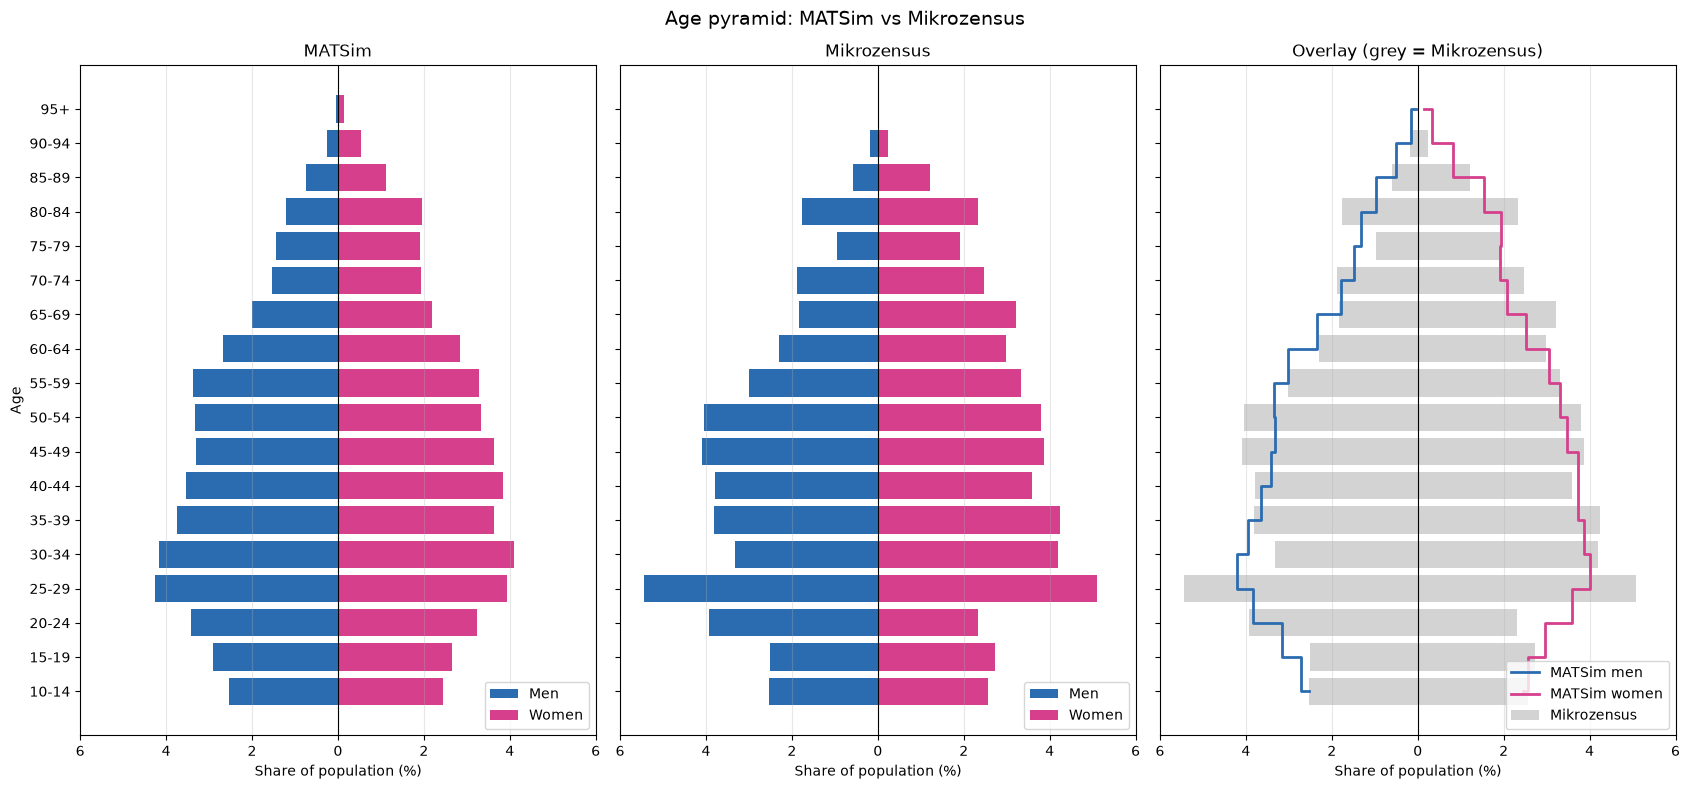

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [11]:
"""
Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)
Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
weighted
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_WIDTH = 5
MAX_AGE = 100
BINS = list(range(10, MAX_AGE + BIN_WIDTH, BIN_WIDTH))
LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
    rows = []
    person = None
    in_plan = False
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
                elif tag == "plan":
                    in_plan = True
            else:
                if tag == "attribute" and person is not None and not in_plan:
                    name = elem.get("name")
                    if name in ("age", "sex", "gender"):
                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()
    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
    n0 = len(df)
    df = df.dropna(subset=["age", "sex"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(
                path,
                sep=None,
                engine="python",
                encoding=enc
            )
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    # -------------------------------------------------- filter households
    hh_file = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")

    hh_ids = pd.read_csv(hh_file)["HHNR"].unique()

    n_before = len(df)
    df = df[df["HHNR"].isin(hh_ids)]
    print(
        f"Household filter: {n_before} -> {len(df)} persons "
        f"({df['HHNR'].nunique()} households)"
    )

    # -------------------------------------------------- age / sex
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)


    n0 = len(df)
    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])

    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")

    return df[["age", "sex", "weight"]]


# ------------------------------------------------------------------ helpers
def shares(df, weight_col=None):
    """% of total population per age bin and sex."""

    ages = df["age"].clip(upper=MAX_AGE)
    bins = pd.cut(ages, bins=BINS, right=False, labels=LABELS)

    if weight_col is None:
        tab = pd.crosstab(bins, df["sex"])
        total = len(df)
    else:
        tmp = pd.DataFrame({
            "age_bin": bins,
            "sex": df["sex"],
            "weight": df[weight_col]
        })

        tab = pd.pivot_table(
            tmp,
            index="age_bin",
            columns="sex",
            values="weight",
            aggfunc="sum",
            fill_value=0,
            observed=False,
        )

        total = tmp["weight"].sum()

    tab = tab.reindex(LABELS, fill_value=0)

    for s in ("m", "f"):
        if s not in tab:
            tab[s] = 0

    return tab[["m", "f"]] / total * 100


def plot(mat, mz):
    y = np.arange(len(LABELS))
    xmax = max(mat.values.max(), mz.values.max()) * 1.1
    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
        ax.set_title(title)

    # overlay comparison
    ax = axes[2]
    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
    ax.barh(y, mz["f"], color="lightgrey")
    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
    ax.set_title("Overlay (grey = Mikrozensus)")

    for ax in axes:
        ax.set_xlim(-xmax, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(LABELS)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
        ax.set_xlabel("Share of population (%)")
        ax.axvline(0, color="black", lw=0.8)
        ax.grid(axis="x", alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Age")
    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_pyramid_w.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    s_mat = shares(matsim)                 # unweighted MATSim
    s_mz  = shares(mz, weight_col="weight")  # weighted Mikrozensus

    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
    out.columns = [f"{a}_{b}" for a, b in out.columns]
    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")


MATSim licence counts:
hasLicense
yes    23052
no     11409
Name: count, dtype: int64

Columns found:
['HHNR', 'WP', 'alter', 'proxi', 'sprache', 'dmod', 'zeit_zp', 'BTag', 'USTag', 'VSTag', 'tag', 'f20400a', 'f20400b', 'f20400c', 'f20400d', 'f40200_01', 'f40202', 'f40203', 'f40300', 'f40400_01a', 'f40400_01b', 'f40400_01c', 'f40400_01d', 'f40400_01e', 'f40400_01f', 'f40400_01g', 'f40402a', 'f40402b', 'f40402c', 'f40402d', 'f40402e', 'f40402f', 'f40402g', 'f40404a', 'f40404b', 'f40404c', 'f40404d', 'f40404e', 'f40404f', 'f40404g', 'f40500', 'f40600', 'f40700', 'f40701', 'f40702', 'f40800_01', 'f40900', 'f40901_02', 'f40903', 'f40904_05', 'f40906', 'f41000a', 'f41000b', 'f41000c', 'f41001a', 'f41001b', 'f41001c', 'f41100_01', 'f41102', 'f41300', 'f41301', 'f41350', 'f41351', 'f41400', 'f41401', 'f41500', 'f41501', 'f80500', 'f80501', 'f80600_01a', 'f80600_01b', 'f80600_01c', 'f80600_01d', 'Berufstamm', 'f81000', 'f81100', 'f81200', 'f81300', 'f81400', 'f81450', 'f50100a', 'f50100b', 'f

C:\Users\Sylvain\AppData\Local\Temp\ipykernel_17032\169071377.py:109: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["hasLicense"] = (
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_17032\169071377.py:117: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["weight"] = (


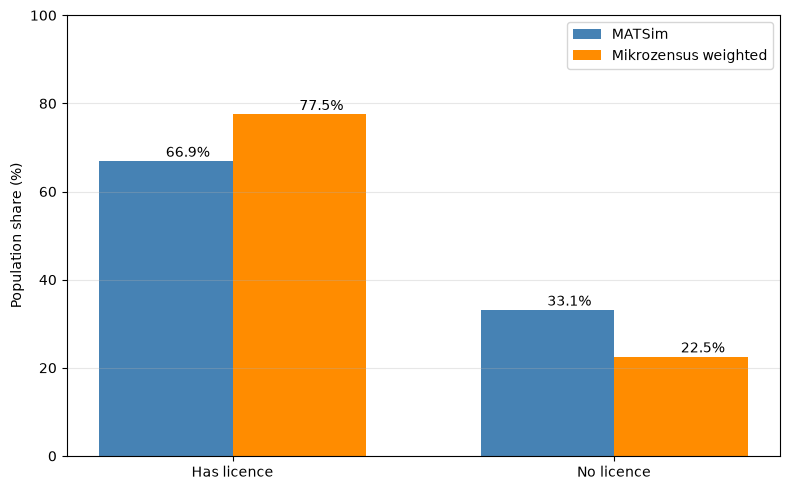

In [10]:
'''liscence
'''

import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths

MATSIM_PATH = Path(
    r"working_rep/filterred_data/lausanne_population_filtered.xml.gz"
)

MZ_PATH = Path(
    r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv"
)

HH_PATH = Path(
    r"working_rep/filterred_data/mz/household_ids_in_area.csv"
)

OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------ MATSim

def read_matsim(path):

    rows = []

    person = None
    in_plan = False

    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):

            if event == "start":

                if elem.tag == "person":
                    person = {}

                elif elem.tag == "plan":
                    in_plan = True

            else:

                if (
                    elem.tag == "attribute"
                    and person is not None
                    and not in_plan
                ):
                    if elem.get("name") == "hasLicense":
                        person["hasLicense"] = (
                            elem.text or ""
                        ).strip().lower()

                elif elem.tag == "plan":
                    in_plan = False

                elif elem.tag == "person":

                    if "hasLicense" in person:
                        rows.append(person)

                    person = None
                    elem.clear()

    df = pd.DataFrame(rows)

    print("\nMATSim licence counts:")
    print(df["hasLicense"].value_counts(dropna=False))

    return df


# ------------------------------------------------------------------ MZ

def read_mz(path):

    for enc in ("utf-8", "cp1252", "latin-1"):

        try:
            df = pd.read_csv(
                path,
                sep=None,
                engine="python",
                encoding=enc,
            )
            break

        except UnicodeDecodeError:
            pass

    print("\nColumns found:")
    print(df.columns.tolist())

    hh_ids = pd.read_csv(HH_PATH)["HHNR"].unique()

    print(f"\nPersons before household filter: {len(df):,}")

    df = df[df["HHNR"].isin(hh_ids)]

    print(f"Persons after household filter: {len(df):,}")

    df["hasLicense"] = (
        pd.to_numeric(df["f20400a"], errors="coerce")
        .map({
            1: "yes",
            2: "no",
        })
    )

    df["weight"] = (
        pd.to_numeric(df["WP"], errors="coerce")
        .fillna(0)
    )

    df = df.dropna(subset=["hasLicense"])

    print("\nMikrozensus licence counts (unweighted):")
    print(df["hasLicense"].value_counts())

    print("\nMikrozensus licence counts (weighted):")
    print(df.groupby("hasLicense")["weight"].sum())

    return df


# ------------------------------------------------------------------ shares

def matsim_share(df):

    counts = (
        df["hasLicense"]
        .value_counts()
        .reindex(["yes", "no"], fill_value=0)
    )

    return counts / counts.sum() * 100


def mz_share(df):

    counts = (
        df.groupby("hasLicense")["weight"]
        .sum()
        .reindex(["yes", "no"], fill_value=0)
    )

    return counts / counts.sum() * 100


# ------------------------------------------------------------------ plot

def plot(mat, mz):

    labels = ["Has licence", "No licence"]

    matsim_vals = [mat["yes"], mat["no"]]
    mz_vals = [mz["yes"], mz["no"]]

    fig, ax = plt.subplots(figsize=(8, 5))

    x = [0, 1]
    width = 0.35

    ax.bar(
        [i - width / 2 for i in x],
        matsim_vals,
        width,
        label="MATSim",
        color="steelblue",
    )

    ax.bar(
        [i + width / 2 for i in x],
        mz_vals,
        width,
        label="Mikrozensus weighted",
        color="darkorange",
    )

    for i, v in enumerate(matsim_vals):
        ax.text(i - width / 2, v + 1, f"{v:.1f}%")

    for i, v in enumerate(mz_vals):
        ax.text(i + width / 2, v + 1, f"{v:.1f}%")

    ax.set_xticks(x)
    ax.set_xticklabels(labels)

    ax.set_ylabel("Population share (%)")
    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        OUT_DIR / "driving_licence_validation.png",
        dpi=300,
    )

    plt.show()


# ------------------------------------------------------------------ main

matsim = read_matsim(MATSIM_PATH)
mz = read_mz(MZ_PATH)

mat_share = matsim_share(matsim)
mz_share_ = mz_share(mz)

print("\nMATSim %")
print(mat_share)

print("\nMikrozensus weighted %")
print(mz_share_)

plot(mat_share, mz_share_)